# Course 2 - Statistical Analysis & Visualisation - Visualization and Storytelling Assignment

### Submitted by Nitish kumar

#### Guidelines

- Go through the data dictionary thoroughly before starting the assignment. That will give you a good idea of what each column represents before you begin the analysis.


- Read each instruction carefully, identify the task to be performed, and only then write the required code. The assignment is meant to be straightforward. You do not need to perform additional analyses that are not requested explicitly. However you are encouraged to perform a few additional analyses to get deeper into the insights


- Some of the tasks might require using functions you may not have used previously. In such cases, you should rely on the library documentation you referred to in the modules. Please understand that completing this assignment is a learning process, and research is part of it.


- Always run the cells of the Notebook sequentially, restart the kernel, and run all the cells to avoid runtime errors.


- For each of the tasks, there's a code cell where you are supposed to write the code and a markdown cell below it mentioning to either write the answer or mention your observations/insights from the output of the code.


- Many of the questions will require you to view them from multiple angles. You have been asked to **observe any trends in the visualizations and provide insights for these trends**. In other words, there will be no fixed answers. You are expected to apply your problem-solving skills to come up with solutions and also document your work appropriately; both of these are part of the assignment grading.

In [1]:
# All important libraries imported

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
plt.style.use('fivethirtyeight')

import warnings
warnings.simplefilter("ignore")

In [2]:
# Dataset loaded as 'df'

df = pd.read_csv('airbnblistings.csv')
df.head()

,id,name,host_id,host_name,host_since_Year,neighbourhood,latitude,longitude,room_type,price,...,last_review,review_scores_rating,review_scores_accuracy,review_scores_cleanliness,review_scores_checkin,review_scores_communication,review_scores_location,review_scores_value,accommodates,bedrooms
0,2818,Quiet Garden View Room & Super Fast WiFi,3159,Daniel,2008,Oostelijk Havengebied - Indische Buurt,52.36435,4.94358,Private room,49,...,2022-06-01,4.89,4.93,5.00,4.97,4.98,4.69,4.82,2,1.0
1,20168,Studio with private bathroom in the centre 1,59484,Alexander,2009,Centrum-Oost,52.36407,4.89393,Private room,106,...,2020-04-09,4.44,4.69,4.79,4.63,4.62,4.87,4.49,2,1.0
2,27886,"Romantic, stylish B&B houseboat in canal district",97647,Flip,2010,Centrum-West,52.38761,4.89188,Private room,126,...,2022-04-24,4.94,4.92,4.95,4.95,4.92,4.89,4.79,2,1.0
3,28871,Comfortable double room,124245,Edwin,2010,Centrum-West,52.36775,4.89092,Private room,75,...,2022-06-04,4.88,4.95,4.90,4.96,4.94,4.97,4.83,2,1.0
4,29051,Comfortable single room,124245,Edwin,2010,Centrum-Oost,52.36584,4.89111,Private room,55,...,2022-06-02,4.79,4.88,4.84,4.92,4.91,4.87,4.76,1,1.0


In [3]:
# Variables for introducing Bold font into print statements

start = "\033[1m"
end = "\033[0;0m"

### Task 1 

#### Basic Descriptive Statistics 

- 1.1 How many AirBnB listings are there in the city of Amsterdam?

In [4]:
print(start + "Answer:" + end + f"The number of AirBnB listings in Amsterdam is {len(df['id'].unique())}.")

Answer:The number of AirBnB listings in Amsterdam is 6173.


- 1.2 What is the average price of all the AirBnB listings in Amsterdam?

In [5]:
print(start + "Answer:" + end + f"The average price of all AirBnB listings in Amsterdam is €{round(np.mean(df['price']), 2)}.")

Answer:The average price of all AirBnB listings in Amsterdam is €198.02.


- 1.3 - What is the average rating received by all the AirBnB listings in Amsterdam? *Hint* - Use the `review_scores_rating` column for answering this question

In [6]:
print(start + "Answer:" + end + f"The average rating of all AirBnB listings in Amsterdam is {round(np.mean(df['review_scores_rating']), 1)}.")

Answer:The average rating of all AirBnB listings in Amsterdam is 4.8.


### Task 2

Plot a histogram for the following variables and observe their distribution. Choose the parameters like bin width, number of bins, etc. as per your choice.

- `price`
- `number_of_reviews`
- `review_scores_rating`

In [7]:
path = 'E:\\Trading Related\\Courses\\upGrad\\Executive Post Graduate Program in Data Science & Machine Learning\\Course 2 - Statistical Analysis & Visualisation\\05 - Visualization and Storytelling Assignment\\Python\\'

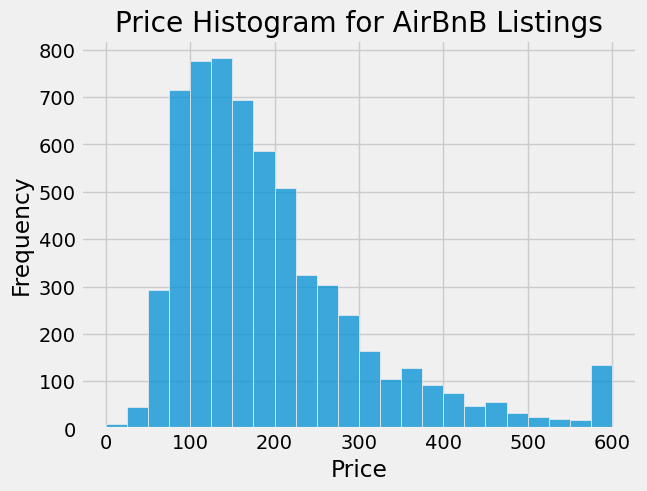

In [8]:
# Overflow bin created at 600, in order to show chart more clearly

sns.histplot(data=df, x=np.clip(df['price'], 0, 600), binwidth=25)
plt.title('Price Histogram for AirBnB Listings')
plt.ylabel('Frequency')
plt.xlabel('Price')
plt.show();

We see that the majority of listings are falling between €50.00 to €300.00.

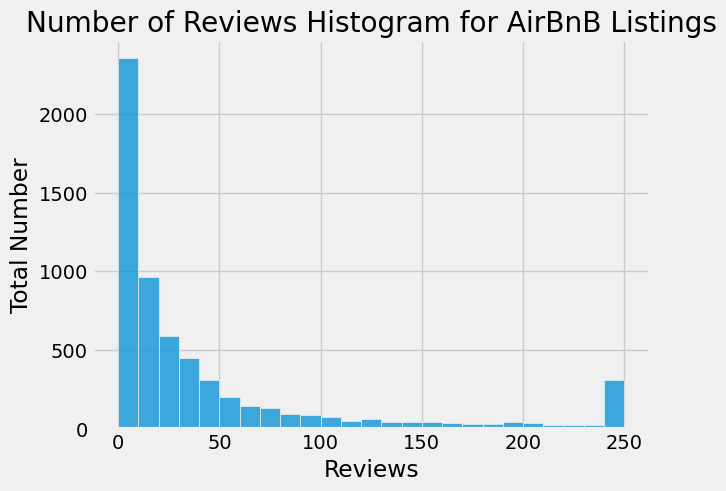

In [9]:
# Overflow bin created at 250, in order to show chart more clearly

sns.histplot(data=df, x=np.clip(df['number_of_reviews'], 0, 250), binwidth=10)
plt.title('Number of Reviews Histogram for AirBnB Listings')
plt.ylabel('Total Number')
plt.xlabel('Reviews')
plt.show();

We see that people are not leaving reviews consistent with occupancy levels, since the distribution is heavily between 0 and 50.

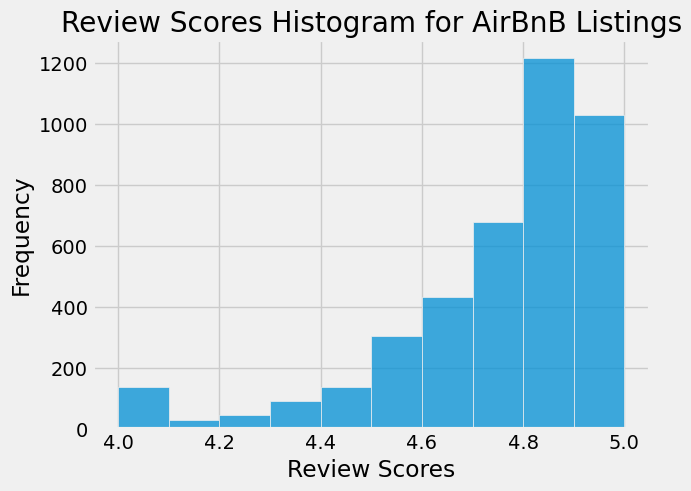

In [10]:
# Underflow bin created at 4.0, in order to show chart more clearly

sns.histplot(data=df, x=np.clip(df['review_scores_rating'], 4, 5), binwidth=0.1)
plt.title('Review Scores Histogram for AirBnB Listings')
plt.ylabel('Frequency')
plt.xlabel('Review Scores')
plt.show();

However, on the other hand, those who are leaving reviews are mostly leaving reviews 4 and above stars.

### Task 3

Plot a visualization to show the number of listings for each `room_type`

Which `room_type` has the highest number of listings?

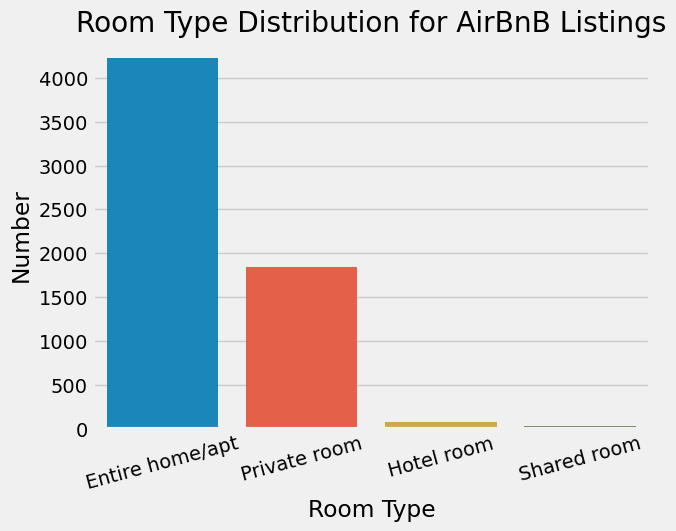

In [11]:
# X Ticks rotated for better visibility

sns.countplot(data=df, x='room_type', order=df['room_type'].value_counts().index)
plt.xticks(rotation=15)
plt.title('Room Type Distribution for AirBnB Listings')
plt.ylabel('Number')
plt.xlabel('Room Type')
plt.show();

The majority of rooms either Entire home/Apartments or Private Rooms.

### Task 4

You want to observe the relationship between the reviews(given by `number_of_reviews`) and the ratings received (`review_scores_rating`) by different AirBnB listings.

For this, plot both a scatterplot and a jointplot. What can you say about the relationship between ratings and reviews?

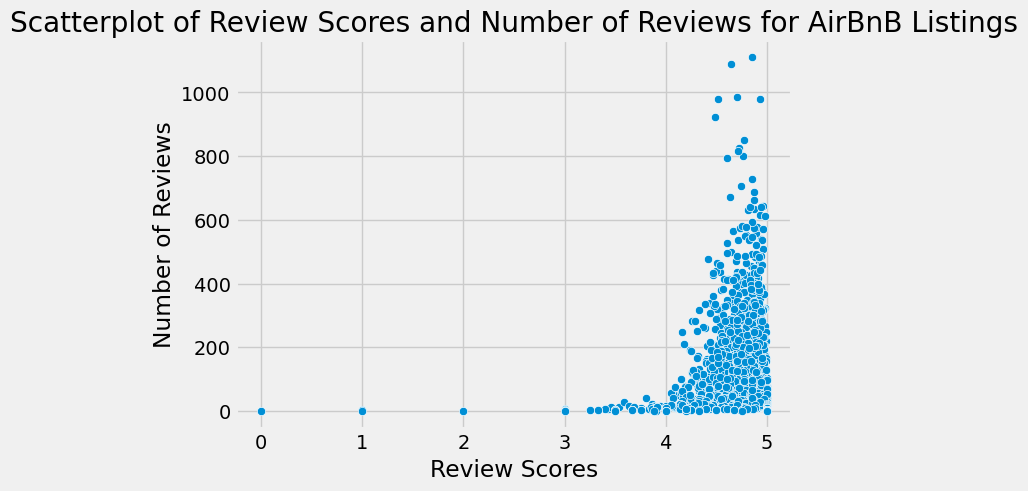

In [12]:
# Scatter plot

j = sns.scatterplot(data=df, x='review_scores_rating', y='number_of_reviews')
plt.title('Scatterplot of Review Scores and Number of Reviews for AirBnB Listings')
plt.ylabel('Number of Reviews')
plt.xlabel('Review Scores')
plt.show();

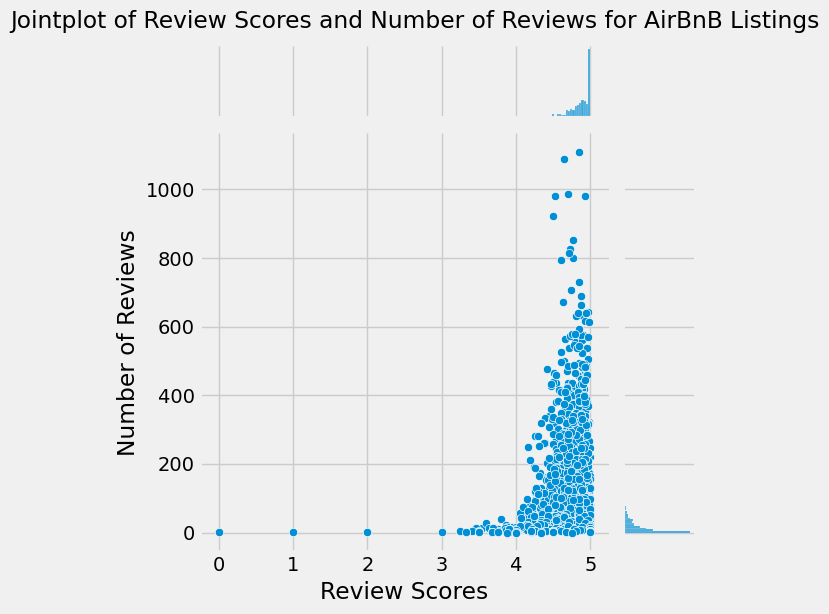

In [13]:
# Joint plot

j = sns.jointplot(data=df, x='review_scores_rating', y='number_of_reviews')
j.fig.suptitle('Jointplot of Review Scores and Number of Reviews for AirBnB Listings', y=1.025)
j.set_axis_labels('Review Scores', 'Number of Reviews')
plt.show();

Majority of the reviewers are satisfied with the accommodation, giving 4.5 stars or above.

### Task 5

AirBnB has been adding quite a few listings in the city of Amseterdam since they started operating in 2008. Plot a lineplot to observe how the average `review_scores_rating` has changed across the different years (use `host_since_Year` column) AirBnB has been operating in the city.

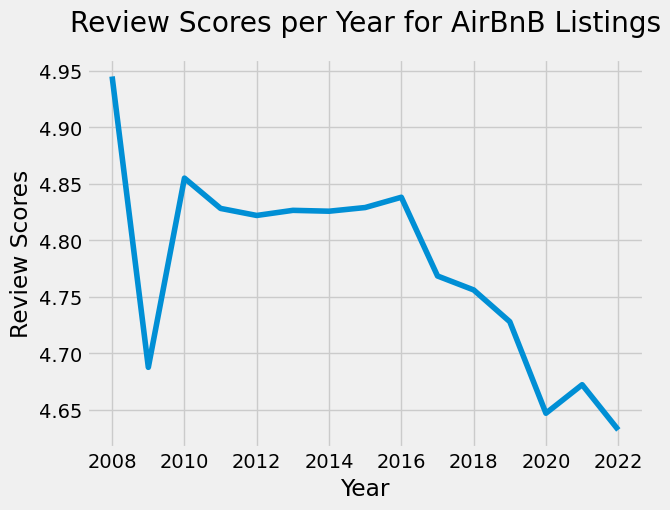

In [14]:
# Data was pivoted for creating a correct visualization

avg_rating_year = df.pivot_table(index='host_since_Year', values='review_scores_rating', aggfunc='mean')

avg_rating_year.index = pd.to_datetime(avg_rating_year.index, format='%Y')

sns.lineplot(data=avg_rating_year, x=avg_rating_year.index, y=avg_rating_year.review_scores_rating)
plt.title('Review Scores per Year for AirBnB Listings', y=1.05)
plt.ylabel('Review Scores')
plt.xlabel('Year')
plt.show();

The average rating is seemingly in a decline.

### Task 6

You wish to identify the relationship between the various ratings each of the listing has received from the customers.
These ratings have been summarized below:

In [15]:
review_columns = ['review_scores_rating',
                  'review_scores_accuracy',
                  'review_scores_cleanliness',
                  'review_scores_checkin',
                  'review_scores_communication',
                  'review_scores_location',
                  'review_scores_value']

In [16]:
# Data loaded into new dataframe and names changed for better charting

new_review_columns = ['Rating',
                      'Accuracy',
                      'Cleanliness',
                      'Check_In',
                      'Communication',
                      'Location',
                      'Value']
df1 = df[review_columns]
df1.columns = new_review_columns

Plot a heatmap of the correlation matrix of the above ratings variables and document your observations. You can use this link to understand these variables further - https://www.airbnb.co.in/help/article/1257/star-ratings

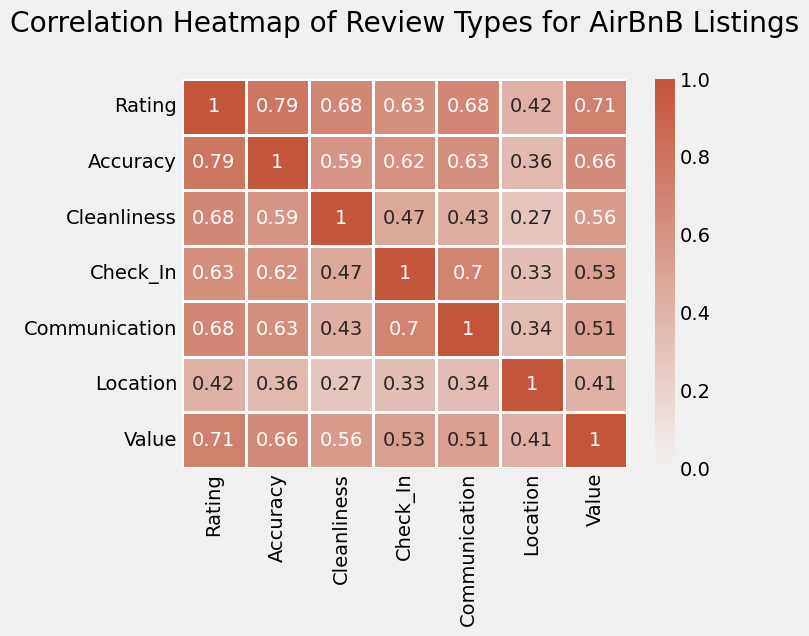

In [17]:
# Heatmap of correlation matrix of new dataframe

sns.heatmap(data=df1.corr(), cmap=sns.diverging_palette(230,20,as_cmap=True), linewidths=1, center=0, vmax=1, vmin=0, annot=True)
plt.title('Correlation Heatmap of Review Types for AirBnB Listings', y=1.1)
plt.show();

Overall Rating is highly correlated with all types of ratings except Location.

### Task 7 

Analyze the listings' prices across the following neighborhoods using a categorical boxplot
- 'Westerpark', 'Oud-Noord', 'Noord-West','Zuid'

In [18]:
# Neighbourhood list

nc = ['Westerpark', 'Oud-Noord', 'Noord-West','Zuid']

In [19]:
# Data subsetting done, so that the data is for only the above neighborhoods

df2 = df[df['neighbourhood'].isin(nc)]

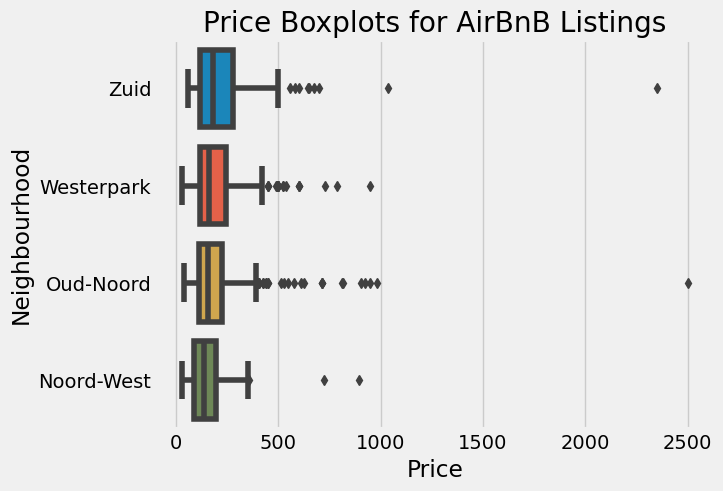

In [20]:
# Categorical boxplot

sns.boxplot(data=df2, x='price', y='neighbourhood')
plt.title('Price Boxplots for AirBnB Listings')
plt.ylabel('Neighbourhood')
plt.xlabel('Price')
plt.show();

Median Prices are less than  €200.00. Any price above €500.00 is definitely an outlier for these 4 neighbourhoods.